In [3]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Vemos los datos

In [4]:
df_datos = pd.read_csv("data/datos_con_probabilidad_impago.csv")
df_datos.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Fiador,Impago,Prima,Estudios_encoded,Estado_Civil_Divorciado,Estado_Civil_Soltero,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Jornada completa,Tipo_Jornada_Laboral_Tiempo parcial,Probabilidad_Impago
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0,0,800.00,2,0,1,0,0,1,0.175035
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0,0,580.00,2,0,0,0,1,0,0.080365
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0,0,130.00,1,0,0,0,0,0,0.102163
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,0,0,168.08,1,0,1,0,0,1,0.087424
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,1,0,293.94,0,0,1,0,1,0,0.150840


In [5]:
df_amortizacion = pd.read_csv('data/clientes_clasificados_frances_aleman.csv')
df_amortizacion.head()

,ID,Monto_Inicial,Ratio_Interes,Duracion,Ingresos,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,000AIY,53671,16.75,48,50294,36.785600,44.553312,1978.435520,20332.799374,325.557721,Francés,True,7.767711,9.730266
1,000OJE,40000,8.83,36,19018,80.060587,88.680899,232.600374,5677.767041,136.617582,Francés,True,8.620312,4.096688
2,000PLV,26187,8.43,48,69183,11.180782,12.653852,246.691329,4753.801366,84.926147,Alemán,False,1.473070,5.189349
3,000Q3U,78378,14.47,36,50507,64.071137,74.182384,1218.728598,18703.227523,425.573952,Francés,True,10.111247,6.516141
4,000TF1,3913,8.42,36,16000,9.253408,10.211300,20.695805,528.635813,12.771889,Alemán,False,0.957892,3.914946


In [6]:
# Seleccionamos las variables nuevas del dataset de amortización
df_amortizacion = df_amortizacion[
    ['ID', 'Esfuerzo_Inicial_Fr', 'Esfuerzo_Inicial_Al',
     'Ahorro_Intereses_Al', 'Intereses_Totales_Fr',
     'Sobreesfuerzo_Inicial_Al', 'Sistema_Recomendado',
     'Ambos_Superan_Limite', 'Diferencia_Esfuerzo',
     'Ahorro_Intereses_Pct']
]

# Unimos los dos datasets por ID
df = df_datos.merge(df_amortizacion,on='ID',how='left')

# Comprobamos el resultado
df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Probabilidad_Impago,Esfuerzo_Inicial_Fr,Esfuerzo_Inicial_Al,Ahorro_Intereses_Al,Intereses_Totales_Fr,Sobreesfuerzo_Inicial_Al,Sistema_Recomendado,Ambos_Superan_Limite,Diferencia_Esfuerzo,Ahorro_Intereses_Pct
0,KG9CT9,34,56572,73978,763,86,1,13.91,60,0.55,...,0.175035,36.439698,44.343385,2940.716995,29095.330653,372.606139,Francés,True,7.903687,10.107178
1,V5O0K9,37,68698,150000,824,162,2,10.53,24,0.37,...,0.080365,121.549207,132.165420,550.623822,17003.748822,607.760466,Francés,True,10.616212,3.238250
2,YE5GD0,40,50000,7490,671,167,2,9.24,60,0.10,...,0.102163,3.752495,4.380152,132.211310,1891.237810,26.152370,Alemán,False,0.627657,6.990729
3,Q6HQ3D,38,63033,11801,649,196,1,7.63,48,0.10,...,0.087424,5.445751,6.108969,91.132177,1929.482123,34.837147,Alemán,False,0.663217,4.723142
4,XO8CO4,19,22301,40000,788,17,4,8.40,36,0.50,...,0.150840,67.845326,74.854640,210.558419,5390.558419,130.262266,Francés,True,7.009314,3.906059


In [7]:
df.columns

Index(['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio',
       'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion',
       'Ratio_Deuda_Ingresos', 'Posesion_Hipoteca', 'Personas_Cargo', 'Fiador',
       'Impago', 'Prima', 'Estudios_encoded', 'Estado_Civil_Divorciado',
       'Estado_Civil_Soltero', 'Tipo_Jornada_Laboral_Desempleado',
       'Tipo_Jornada_Laboral_Jornada completa',
       'Tipo_Jornada_Laboral_Tiempo parcial', 'Probabilidad_Impago',
       'Esfuerzo_Inicial_Fr', 'Esfuerzo_Inicial_Al', 'Ahorro_Intereses_Al',
       'Intereses_Totales_Fr', 'Sobreesfuerzo_Inicial_Al',
       'Sistema_Recomendado', 'Ambos_Superan_Limite', 'Diferencia_Esfuerzo',
       'Ahorro_Intereses_Pct'],
      dtype='object')

In [8]:
df.isna().sum()

ID                                       0
Edad                                     0
Ingresos                                 0
Monto_Inicial                            0
Scoring_Crediticio                       0
Meses_Empleo                             0
Num_Creditos                             0
Ratio_Interes                            0
Duracion                                 0
Ratio_Deuda_Ingresos                     0
Posesion_Hipoteca                        0
Personas_Cargo                           0
Fiador                                   0
Impago                                   0
Prima                                    0
Estudios_encoded                         0
Estado_Civil_Divorciado                  0
Estado_Civil_Soltero                     0
Tipo_Jornada_Laboral_Desempleado         0
Tipo_Jornada_Laboral_Jornada completa    0
Tipo_Jornada_Laboral_Tiempo parcial      0
Probabilidad_Impago                      0
Esfuerzo_Inicial_Fr                      0
Esfuerzo_In

In [10]:
correlacion_prima = df.corr(numeric_only=True)['Prima'].drop('Prima')

print(
    correlacion_prima.reindex(
        correlacion_prima.abs().sort_values(ascending=False).index
    )
)

Intereses_Totales_Fr                     0.640481
Ratio_Deuda_Ingresos                     0.634848
Diferencia_Esfuerzo                      0.624056
Monto_Inicial                            0.623751
Sobreesfuerzo_Inicial_Al                 0.593188
Sistema_Amortizacion                    -0.560777
Ambos_Superan_Limite                     0.525921
Ahorro_Intereses_Al                      0.524219
Esfuerzo_Inicial_Al                      0.389071
Esfuerzo_Inicial_Fr                      0.357788
Ahorro_Intereses_Pct                     0.320555
Duracion                                 0.310915
Ingresos                                 0.210108
Ratio_Interes                            0.137550
Estudios_encoded                         0.126992
Edad                                     0.114118
Estado_Civil_Soltero                    -0.108103
Meses_Empleo                             0.083599
Scoring_Crediticio                      -0.074147
Probabilidad_Impago                     -0.058173


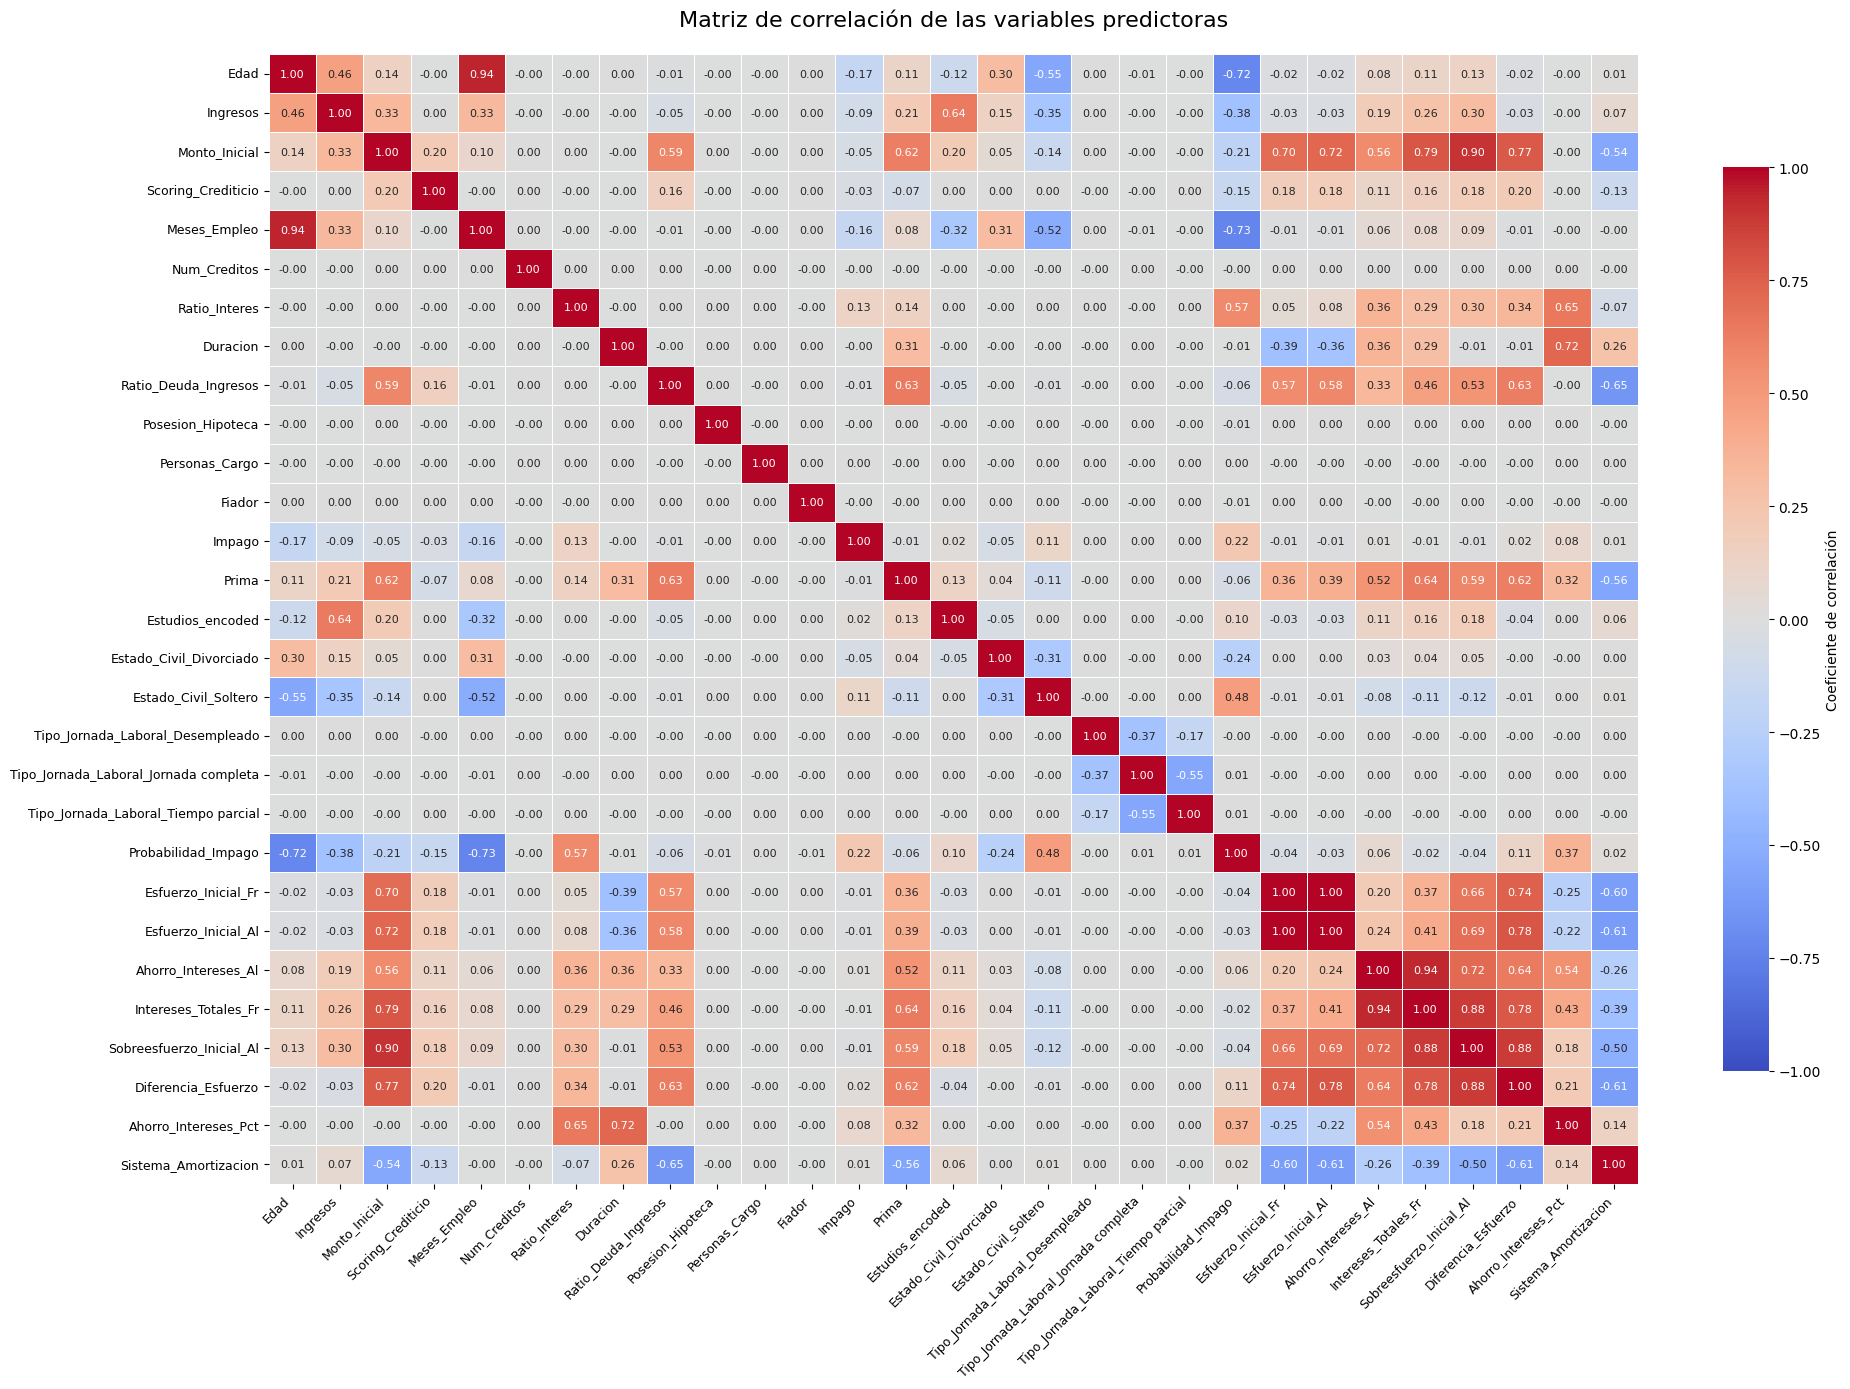

In [11]:
# Matriz de correlación de las variables que realmente entran al modelo
df_num = df.select_dtypes(include=['int64', 'float64'])
correlacion = df_num.corr()

plt.figure(figsize=(20, 14))

sns.heatmap(
    correlacion,
    annot=True,          # Mostrar los valores
    fmt=".2f",           # Dos decimales
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 8},
    cbar_kws={
        "label": "Coeficiente de correlación",
        "shrink": 0.8
    }
)

plt.title(
    "Matriz de correlación de las variables predictoras",
    fontsize=16,
    pad=20
)

plt.xticks(
    rotation=45,
    ha="right",
    fontsize=9
)

plt.yticks(
    rotation=0,
    fontsize=9
)

plt.tight_layout()
plt.show()

# Preparamos los datos 

In [9]:
# Convertimos el sistema recomendado a números
df['Sistema_Amortizacion'] = df['Sistema_Recomendado'].map({
    'Alemán': 1,
    'Francés': 0
})

# Seleccionamos las variables predictoras
X = df[[
    'Edad',
    'Ingresos',
    'Monto_Inicial',
    'Scoring_Crediticio',
    'Meses_Empleo',
    'Num_Creditos',
    'Ratio_Interes',
    'Duracion',
    'Ratio_Deuda_Ingresos',
    'Posesion_Hipoteca',
    'Personas_Cargo',
    'Fiador',
    'Estudios_encoded',
    'Estado_Civil_Divorciado',
    'Estado_Civil_Soltero',
    'Tipo_Jornada_Laboral_Desempleado',
    'Tipo_Jornada_Laboral_Jornada completa',
    'Tipo_Jornada_Laboral_Tiempo parcial',
    'Ahorro_Intereses_Al',
    'Intereses_Totales_Fr',
    'Diferencia_Esfuerzo',
    'Sistema_Amortizacion'
]]

# Variable que queremos predecir
y = df['Prima']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


## Probamos un modelo de regresión lineal simple

In [12]:
# Estandarizamos las variables
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = scaler.transform(X_test)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

In [13]:
X_train_scaled = sm.add_constant(X_train_scaled, prepend=True)
modelo_lin_reg = sm.OLS(endog=y_train, exog=X_train_scaled)
modelo_lin_reg = modelo_lin_reg.fit()
print(modelo_lin_reg.summary())

                            OLS Regression Results                            
Dep. Variable:                  Prima   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.759
Method:                 Least Squares   F-statistic:                 2.042e+04
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:30:27   Log-Likelihood:            -8.9993e+05
No. Observations:              142884   AIC:                         1.800e+06
Df Residuals:                  142861   BIC:                         1.800e+06
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

In [14]:
## Evaluamos el modelo
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error, r2_score

# Añadir la constante al conjunto de test
X_test_scaled = sm.add_constant(X_test_scaled, prepend=True)

# Realizar las predicciones
prediccion_test_scaled = modelo_lin_reg.predict(exog=X_test_scaled)

# Cálculo de métricas de error
mse = mean_squared_error(y_true=y_test, y_pred=prediccion_test_scaled)
rmse = root_mean_squared_error(y_true=y_test, y_pred=prediccion_test_scaled)
mae = mean_absolute_error(y_true=y_test, y_pred=prediccion_test_scaled)
print(f"Primeras cinco predicciones: {prediccion_test_scaled[0:5]}")
print(f"El error (mse) de test es: {round(mse,2)}")
print(f"El error (rmse) de test es: {round(rmse,2)}")
print(f"El error (mae) de test es: {round(mae,2)}")

Primeras cinco predicciones: 78049     497.135210
115875    116.378556
22543     397.321510
119699    404.239917
164399    305.473379
dtype: float64
El error (mse) de test es: 17286.25
El error (rmse) de test es: 131.48
El error (mae) de test es: 103.78


# Comprobamos los supuestos

In [15]:
# Residuos de las predicciones de entrenamiento
prediccion_train_scaled = modelo_lin_reg.predict(exog=X_train_scaled)
residuos_train_scaled = y_train - prediccion_train_scaled # residuos = valores reales - predicciones

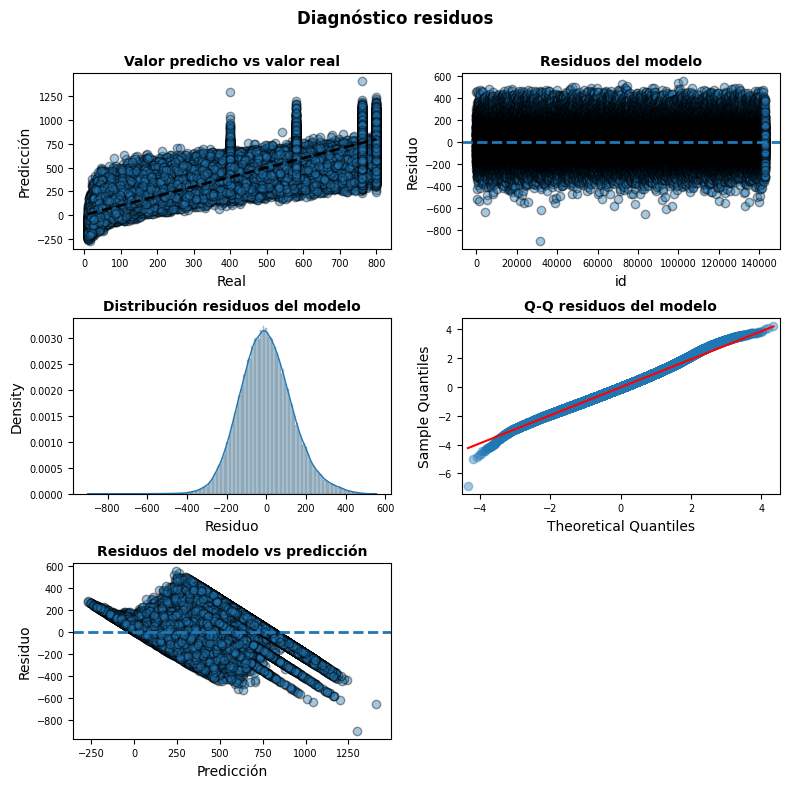

In [16]:
# Gráficos
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 8))

axes[0, 0].scatter(y_train, prediccion_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', lw=2)
axes[0, 0].set_title('Valor predicho vs valor real', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicción')
axes[0, 0].tick_params(labelsize = 7)

axes[0, 1].scatter(list(range(len(y_train))), residuos_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 1].axhline(y = 0, linestyle = '--', lw=2)
axes[0, 1].set_title('Residuos del modelo', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residuo')
axes[0, 1].tick_params(labelsize = 7)

sns.histplot(
    data    = residuos_train_scaled,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribución residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize = 7)


sm.qqplot(
    residuos_train_scaled,
    fit   = True, # estandariza los residuos con su ppropia media y desviación típica
    line  = 'q',
    ax    = axes[1, 1], 
    alpha = 0.4,
    lw    = 2
)
axes[1, 1].set_title('Q-Q residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)

axes[2, 0].scatter(prediccion_train_scaled, residuos_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[2, 0].axhline(y = 0, linestyle = '--', lw=2)
axes[2, 0].set_title('Residuos del modelo vs predicción', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Predicción')
axes[2, 0].set_ylabel('Residuo')
axes[2, 0].tick_params(labelsize = 7)

# Se eliminan los axes vacíos
fig.delaxes(axes[2, 1])
fig.tight_layout() # Recoloca automáticamente los gráficos para que títulos y etiquetas no se solapen
plt.subplots_adjust(top=0.9) # Deja libre el 10% superior de la figura para el título general
fig.suptitle('Diagnóstico residuos', fontsize = 12, fontweight = "bold");

In [17]:
# Prueba de normalidad de Shapiro-Wilk
from scipy import stats
shapiro_test = stats.shapiro(residuos_train_scaled)
shapiro_test

c:\Users\Gaizka\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 142884.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9964328929799783), pvalue=np.float64(4.2896755875206527e-44))

In [18]:
# Prueba de normalidad de D'Agostino y Pearson

k2, p_value = stats.normaltest(residuos_train_scaled)
print(f"Estadítico= {k2}, p-value = {p_value}")

Estadítico= 1500.2717672450722, p-value = 0.0


## Pruebas de modelado con diferentes grados polinómicos

In [19]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error, r2_score

# Particiones de validación cruzada: las mismas para todos los modelos
cv = KFold(n_splits=5, shuffle=True, random_state=42)

In [20]:
def preparar(X_tr, X_val, grado):
    # Crea el polinomio y estandariza. Se ajusta solo con los datos de entrenamiento (fit)
    # y se aplica a los de validación (transform), para no usar información de validación
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    A = poly.fit_transform(X_tr)
    B = poly.transform(X_val)
    scaler = StandardScaler()
    A = scaler.fit_transform(A)
    B = scaler.transform(B)
    return A, B

In [21]:
def rmse_cv(modelo, grado, X, y):
    # Devuelve el RMSE medio de validación cruzada y su desviación entre folds
    errores = [] # lista donde se guardará el error de cada fold
    for idx_train, idx_val in cv.split(X): 
        # cv es el objeto de validación cruzada definido fuera de la función (global). Su método split devuelve en cada vuelta los índices de las filas que van a entrenamiento y a validación. Se repite una vez por fold.
        A, B = preparar(X.iloc[idx_train], X.iloc[idx_val], grado)   # preparamos los datos de este fold
        modelo.fit(A, y.iloc[idx_train])                              # entrenamos con el fold de entrenamiento
        pred = modelo.predict(B)                                      # predecimos el fold de validación
        errores.append(root_mean_squared_error(y.iloc[idx_val], pred))
    return np.mean(errores), np.std(errores)
    # Devuelve dos números: el RMSE medio entre folds (qué tan bien rinde el modelo) y su desviación típica (qué tan estable es entre folds)

In [22]:
# Probamos los grados 1 a 3 y guardamos el error de cada uno
resultados = []
for grado in [1, 2, 3]:
    media, desviacion = rmse_cv(LinearRegression(), grado, X_train, y_train)
    resultados.append({"grado": grado, "RMSE_cv": media, "desviacion_cv": desviacion})

resultados_cv = pd.DataFrame(resultados)
print(resultados_cv.round(2))

   grado  RMSE_cv  desviacion_cv
0      1   131.58           0.46
1      2    79.08           0.31
2      3    65.35           0.47


## Evaluamos el modelo con grado 3

In [23]:
# Preparamos los datos de grado 3 (polinomio y estandarización ajustados con train)
A_train, A_test = preparar(X_train, X_test, 3)

# Entrenamos con todo el train
modelo_grado3 = LinearRegression()
modelo_grado3.fit(A_train, y_train)

# Predicciones y métricas en train y test
pred_train = modelo_grado3.predict(A_train)
pred_test = modelo_grado3.predict(A_test)
print(f"Train: RMSE = {root_mean_squared_error(y_train, pred_train):.2f} | MAE = {mean_absolute_error(y_train, pred_train):.2f} | R² = {r2_score(y_train, pred_train):.3f}")
print(f"Test:  RMSE = {root_mean_squared_error(y_test, pred_test):.2f} | MAE = {mean_absolute_error(y_test, pred_test):.2f} | R² = {r2_score(y_test, pred_test):.3f}")

Train: RMSE = 63.65 | MAE = 46.23 | R² = 0.944
Test:  RMSE = 64.51 | MAE = 46.82 | R² = 0.942


## Curvas de aprendizaje comparativa entre grados

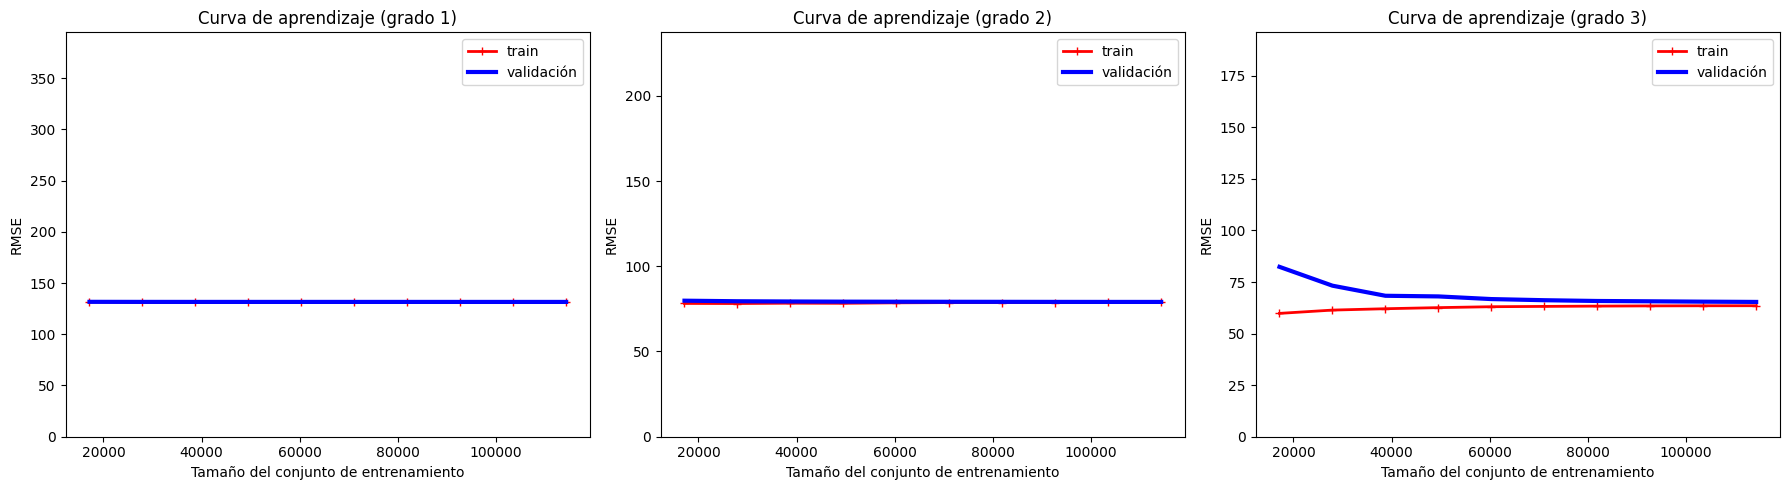

In [24]:
from sklearn.model_selection import learning_curve

def curva_aprendizaje(X, y, grado, ax):
    """Dibuja la curva de aprendizaje de una regresión polinómica del grado indicado en el gráfico ax."""

    # Creamos las variables polinómicas y las estandarizamos
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    X_poly = poly.fit_transform(X)
    X_poly = StandardScaler().fit_transform(X_poly)

    # Entrena con cantidades crecientes de datos y mide el error en train y en validación
    train_sizes, train_scores, valid_scores = learning_curve(
        LinearRegression(), X_poly, y,
        train_sizes=np.linspace(0.15, 1.0, 10),   # del 15 % al 100 % de cada fold de entrenamiento
        cv=cv,
        scoring="neg_root_mean_squared_error")

    # Media de los 5 folds, con el signo cambiado para que el error sea positivo
    train_errors = -train_scores.mean(axis=1)
    valid_errors = -valid_scores.mean(axis=1)

    ax.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
    ax.plot(train_sizes, valid_errors, "b-", linewidth=3, label="validación")

    # Limitamos el eje Y para que los errores grandes del principio no aplasten el resto
    ax.set_ylim(0, 3 * valid_errors.min())

    ax.set_xlabel("Tamaño del conjunto de entrenamiento")
    ax.set_ylabel("RMSE")
    ax.set_title(f"Curva de aprendizaje (grado {grado})")
    ax.legend()

# Un gráfico por grado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, grado in zip(axes, [1, 2, 3]):
    curva_aprendizaje(X_train, y_train, grado, ax)

plt.tight_layout()
plt.show()

# Pruebas de regularización

In [25]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from scipy.stats import loguniform

# Datos de grado 3: creamos el polinomio y estandarizamos con todo el train
poly = PolynomialFeatures(degree=3, include_bias=False)
scaler = StandardScaler()
X_train_poly = scaler.fit_transform(poly.fit_transform(X_train))
X_test_poly = scaler.transform(poly.transform(X_test))   # al test solo se le aplica transform

## 1. Lasso

In [26]:
# Búsqueda de Lasso
random_lasso = RandomizedSearchCV(
    estimator=Lasso(max_iter=1000, tol=0.01, selection="random"),
    param_distributions={"alpha": loguniform(1, 1000)},
    n_iter=3,
    cv=2,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=2
)

In [27]:
random_lasso.fit(X_train_poly, y_train)

Fitting 2 folds for each of 3 candidates, totalling 6 fits
[CV] END ...........................alpha=13.292918943162162; total time=  16.1s
[CV] END ...........................alpha=13.292918943162162; total time=  11.4s
[CV] END ............................alpha=711.4476009343418; total time=   5.9s
[CV] END ............................alpha=711.4476009343418; total time=   5.6s
[CV] END ............................alpha=157.0297088405538; total time=   7.2s
[CV] END ............................alpha=157.0297088405538; total time=   8.5s


,estimator,"Lasso(selecti...om', tol=0.01)"
,param_distributions,{'alpha': <scipy.stats....00232D15ACB90>}
,n_iter,3
,scoring,'neg_root_mean_squared_error'
,n_jobs,1
,refit,True
,cv,2
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [28]:
print("Lasso")
print("Mejores parámetros:", random_lasso.best_params_)
print("RMSE cv:", round(-random_lasso.best_score_, 2))

Lasso
Mejores parámetros: {'alpha': np.float64(13.292918943162162)}
RMSE cv: 115.29


## 2.Ridge

In [29]:
# Rango de alpha de cada modelo. Usamos RMSE para poder compararlos con los grados
random_ridge = RandomizedSearchCV(
    estimator=Ridge(),
    param_distributions={"alpha": loguniform(0.01, 1000)},
    n_iter=10,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=2
)

In [30]:
random_ridge.fit(X_train_poly, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END ...........................alpha=0.7459343285726545; total time=   4.6s
[CV] END ...........................alpha=0.7459343285726545; total time=   4.6s
[CV] END ...........................alpha=0.7459343285726545; total time=   5.7s
[CV] END ............................alpha=566.9849511478844; total time=   5.2s
[CV] END ............................alpha=566.9849511478844; total time=   4.7s
[CV] END ............................alpha=566.9849511478844; total time=   5.4s
[CV] END ............................alpha=45.70563099801453; total time=   4.9s
[CV] END ............................alpha=45.70563099801453; total time=   5.7s
[CV] END ............................alpha=45.70563099801453; total time=   5.6s
[CV] END ............................alpha=9.846738873614559; total time=   5.9s
[CV] END ............................alpha=9.846738873614559; total time=   5.2s
[CV] END ............................alpha=9.846

,estimator,Ridge()
,param_distributions,{'alpha': <scipy.stats....00232D15F3110>}
,n_iter,10
,scoring,'neg_root_mean_squared_error'
,n_jobs,1
,refit,True
,cv,3
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [31]:
print("Ridge")
print("Mejores parámetros:", random_ridge.best_params_)
print("RMSE cv:", round(-random_ridge.best_score_, 2))

Ridge
Mejores parámetros: {'alpha': np.float64(0.0195172246414495)}
RMSE cv: 66.01


## 3. ElasticNet

In [32]:
# Búsqueda de ElasticNet
random_elastic = RandomizedSearchCV(
    estimator=ElasticNet(max_iter=5000, tol=0.01, selection="random"),
    param_distributions={
        "alpha": loguniform(1, 1000),
        "l1_ratio": [0.1, 0.5, 0.75, 0.9, 1.0]
    },
    n_iter=3,
    cv=2,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=2
)

In [33]:
random_elastic.fit(X_train_poly, y_train)

Fitting 2 folds for each of 3 candidates, totalling 6 fits
[CV] END .............alpha=13.292918943162162, l1_ratio=1.0; total time=  14.5s
[CV] END .............alpha=13.292918943162162, l1_ratio=1.0; total time=  13.0s
[CV] END ..............alpha=3.550621427070769, l1_ratio=1.0; total time=  14.2s
[CV] END ..............alpha=3.550621427070769, l1_ratio=1.0; total time=  14.7s
[CV] END ..............alpha=61.73770394704569, l1_ratio=0.5; total time=   8.5s
[CV] END ..............alpha=61.73770394704569, l1_ratio=0.5; total time=   8.3s


,estimator,"ElasticNet(ma...om', tol=0.01)"
,param_distributions,"{'alpha': <scipy.stats....00232C9147100>, 'l1_ratio': [0.1, 0.5, ...]}"
,n_iter,3
,scoring,'neg_root_mean_squared_error'
,n_jobs,1
,refit,True
,cv,2
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [34]:
print("ElasticNet")
print("Mejores parámetros:", random_elastic.best_params_)
print("RMSE cv:", round(-random_elastic.best_score_, 2))

ElasticNet
Mejores parámetros: {'alpha': np.float64(3.550621427070769), 'l1_ratio': 1.0}
RMSE cv: 97.17


## 4. Sin regularizar

In [35]:
sin_reg = cross_val_score(
    LinearRegression(),
    X_train_poly,
    y_train,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)

print("Sin regularizar (grado 3), RMSE cv:", round(-sin_reg.mean(), 2))

Sin regularizar (grado 3), RMSE cv: 66.04


Al comparar los modelos, Ridge obtiene el menor RMSE de validación cruzada, con un valor de 66,01. Sin embargo, el modelo sin regularizar obtiene un resultado prácticamente igual, con un RMSE de 66,04. Esto indica que la regularización Ridge apenas mejora el resultado. En cambio, Lasso y ElasticNet presentan errores más elevados, por lo que funcionan peor con la configuración probada. Por tanto, elegiría Ridge, aunque la mejora respecto al modelo sin regularizar es muy pequeña.

# Modelo final

In [36]:
modelo_final = random_ridge.best_estimator_
print("Modelo final: Ridge")
print("Mejores parámetros:", random_ridge.best_params_)

# Métricas en train y test
pred_train = modelo_final.predict(X_train_poly)
pred_test = modelo_final.predict(X_test_poly)
print(f"Train: RMSE = {root_mean_squared_error(y_train, pred_train):.2f} | MAE = {mean_absolute_error(y_train, pred_train):.2f} | R² = {r2_score(y_train, pred_train):.3f}")
print(f"Test:  RMSE = {root_mean_squared_error(y_test, pred_test):.2f} | MAE = {mean_absolute_error(y_test, pred_test):.2f} | R² = {r2_score(y_test, pred_test):.3f}")

Modelo final: Ridge
Mejores parámetros: {'alpha': np.float64(0.0195172246414495)}
Train: RMSE = 63.93 | MAE = 46.48 | R² = 0.943
Test:  RMSE = 64.61 | MAE = 47.03 | R² = 0.941


## Descenso de gradiente

In [47]:
from sklearn.linear_model import SGDRegressor # Cargamos la clase SGDRegressor, que implementa el descenso de gradiente estocástico para regresión lineal y regularización L1/L2.

alpha = modelo_final.alpha   # penalización del modelo final (el de ridge y polinomio 3)

from sklearn.preprocessing import StandardScaler

scaler_sgd = StandardScaler()
X_train_sgd = scaler_sgd.fit_transform(X_train_poly)
X_test_sgd = scaler_sgd.transform(X_test_poly)


sgd = SGDRegressor(
    loss="squared_error",
    penalty="l2",
    alpha=alpha,
    learning_rate="adaptive",
    eta0=0.001,
    max_iter=5000,
    tol=0.001,
    n_iter_no_change=10,
    random_state=42
)

sgd.fit(X_train_sgd, y_train)

b_sgd = sgd.intercept_[0]   # intercepto 
w_sgd = sgd.coef_           # pesos

print(f"MSE test: {round(mean_squared_error(y_test, sgd.predict(X_test_poly)), 2)}")
print(f"RMSE test: {round(root_mean_squared_error(y_test, sgd.predict(X_test_poly)), 2)}")
print(f"MAE test: {round(mean_absolute_error(y_test, sgd.predict(X_test_poly)), 2)}")

MSE test: 6003.97
RMSE test: 77.49
MAE test: 58.66


In [48]:
# Comparamos los coeficientes del SGDRegressor con los de scikit-learn
nombres = poly.get_feature_names_out()
comparacion = pd.DataFrame({
    "SGDRegressor": np.r_[sgd.intercept_, sgd.coef_],
    "sklearn": np.r_[modelo_final.intercept_, modelo_final.coef_]
}, index=["intercepto", *nombres])

comparacion["diferencia"] = (
    comparacion["SGDRegressor"] - comparacion["sklearn"]
).abs()

print(comparacion.round(2))

# RMSE en test con el SGDRegressor
pred_sgd = sgd.predict(X_test_sgd)

print("RMSE test (SGDRegressor):", round(root_mean_squared_error(y_test, pred_sgd), 2))
print("RMSE test (Ridge):       ", round(root_mean_squared_error(y_test, pred_test), 2))

                                             SGDRegressor  sklearn  diferencia
intercepto                                         386.86   386.87        0.00
Edad                                                -4.59   102.21      106.80
Ingresos                                             4.02  -446.58      450.60
Monto_Inicial                                       23.32   801.15      777.82
Scoring_Crediticio                                  44.78  -304.34      349.12
...                                                   ...      ...         ...
Intereses_Totales_Fr Sistema_Amortizacion^2         13.64  -349.33      362.97
Diferencia_Esfuerzo^3                               15.08     4.23       10.85
Diferencia_Esfuerzo^2 Sistema_Amortizacion           3.53   -16.23       19.76
Diferencia_Esfuerzo Sistema_Amortizacion^2           1.94     0.22        1.72
Sistema_Amortizacion^3                             -16.13   118.21      134.33

[2300 rows x 3 columns]
RMSE test (SGDRegressor): 7

El descenso de gradiente estocástico (SGDRegressor) obtiene un RMSE de test de 77,51, superior al del modelo Ridge de sklearn (64,61). Los coeficientes presentan diferencias importantes en algunas variables, como Edad (−3,04 frente a 102,21), Ingresos (4,16 frente a −446,58) y Monto_Inicial (22,72 frente a 801,15). Esto puede deberse a que el SGD no ha convergido suficientemente bien y a que hay muchas variables polinómicas con escalas diferentes. Por eso, nos quedamos con el modelo Ridge de sklearn como modelo final, ya que obtiene mejores resultados en test.

## Coeficientes del modelo final


In [51]:
# Mostramos el intercepto
print("Intercepto:", modelo_final.intercept_)

nombres = poly.get_feature_names_out(X_train.columns)
coeficientes = pd.Series(modelo_final.coef_, index=nombres)

print(coeficientes[X_train.columns])

Intercepto: 386.86736786479327
Edad                                      102.213689
Ingresos                                 -446.581588
Monto_Inicial                             801.145027
Scoring_Crediticio                       -304.343716
Meses_Empleo                             -168.961391
Num_Creditos                               44.667797
Ratio_Interes                            -132.836960
Duracion                                 -469.402702
Ratio_Deuda_Ingresos                     -253.265979
Posesion_Hipoteca                          -4.401697
Personas_Cargo                              8.266843
Fiador                                      7.734724
Estudios_encoded                          -65.859273
Estado_Civil_Divorciado                    -1.442404
Estado_Civil_Soltero                        3.987381
Tipo_Jornada_Laboral_Desempleado            2.724641
Tipo_Jornada_Laboral_Jornada completa       4.810864
Tipo_Jornada_Laboral_Tiempo parcial        11.064644
Ahorro_Interese

In [55]:
print("X:", X.shape)
print("X_poly:", X_poly.shape)
print("Número de variables que espera el scaler:", scaler.n_features_in_)
print("Número de variables que espera poly:", poly.n_features_in_)
print("Número de coeficientes del modelo:", len(modelo_final.coef_))
print("Número de variables del entrenamiento:", X_train.shape)

X: (178606, 22)
X_poly: (178606, 2299)
Número de variables que espera el scaler: 2299
Número de variables que espera poly: 22
Número de coeficientes del modelo: 2299
Número de variables del entrenamiento: (142884, 22)


## Primas

In [56]:
# Creamos las variables polinómicas de todos los clientes
X_poly = poly.transform(X)

# Escalamos las variables polinómicas
X_poly_scal = scaler.transform(X_poly)

# Calculamos la prima estimada con el modelo final
primas_estimadas = modelo_final.predict(X_poly_scal)

# Creamos un DataFrame con los resultados
df_primas = df.copy()
df_primas['Prima_Estimada'] = primas_estimadas

# Calculamos la diferencia entre la prima real y la estimada
df_primas["diferencia"] = df_primas["Prima"] - df_primas["Prima_Estimada"]

# Mostramos los resultados
df_primas[['ID', 'Prima', 'Prima_Estimada', 'diferencia']]

,ID,Prima,Prima_Estimada,diferencia
0,KG9CT9,800.00,817.267263,-17.267263
1,V5O0K9,580.00,516.232330,63.767670
2,YE5GD0,130.00,125.544194,4.455806
3,Q6HQ3D,168.08,165.291571,2.788429
4,XO8CO4,293.94,347.210624,-53.270624
...,...,...,...,...
178601,VLZOS9,760.00,790.239213,-30.239213
178602,Z0BY9Y,542.47,631.929412,-89.459412
178603,ARBQ2V,188.19,147.166727,41.023273
178604,1LVUEW,58.46,82.135292,-23.675292


**Modelo elegido:** Ridge (alpha ≈ 0,0195) sobre variables polinómicas de grado 3 para predecir la prima del seguro. Es el modelo seleccionado mediante búsqueda de hiperparámetros y validación cruzada. Obtuvo un RMSE de validación cruzada de aproximadamente 66,01, muy parecido al del modelo polinómico sin regularizar (66,04). En el conjunto de test, obtuvo un RMSE de 64,61.

**Fórmula:**
Prima=386,87 + Σ βⱼ · (φⱼ − μⱼ) / σⱼ

donde (σⱼ) representa las variables originales y los términos polinómicos de grado 2 y 3, como Edad, Ingresos, Edad², Edad × Ingresos y otras combinaciones entre las características de los clientes. Los \(\beta_j\) son los coeficientes estimados por Ridge y 386,87 es el intercepto del modelo.

Entre los coeficientes de mayor valor absoluto se encuentran Intereses_Totales_Fr² × Diferencia_Esfuerzo (−4669,76), Monto_Inicial × Ahorro_Intereses_Al × Diferencia_Esfuerzo (3606,65) y Ratio_Interes × Ahorro_Intereses_Al (−2959,29). Estos valores corresponden a términos concretos del polinomio, no a variables individuales.

**Cómo se lee:** El modelo utiliza las características económicas y personales de cada cliente, junto con sus combinaciones polinómicas, para estimar la prima del seguro. Ridge aplica regularización L2 para reducir el tamaño de los coeficientes y limitar el sobreajuste. A diferencia de Lasso, Ridge no elimina variables dejando sus coeficientes exactamente en cero.